In [1]:
import torch
import torch.distributions as dist
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import FastICA

from engression.loss_func import energy_loss, energy_loss_two_sample

from sem2 import SEM2
from model.nn_models import MLP
from Amari_error import Amari_error

In [3]:
def generate_data(n_samples=5000, A_true=None, Sigma=None):
    A_true = torch.tensor(A_true,dtype=torch.float32) if isinstance(A_true, np.ndarray) else A_true
    n_features, n_sources = A_true.shape
    S1_true = dist.Gamma(2.0, 1.0).sample((n_samples,))
    S2_true = dist.Beta(2.0, 5.0).sample((n_samples,))
    S_true = torch.stack([S1_true, S2_true], dim=0)  # Shape: (n_sources, n_samples)
    X_clean = A_true @ S_true  # Shape: (n_features, n_samples)

    if Sigma is None:
        X_noisy = X_clean.T
    else:
        Sigma = torch.tensor(Sigma,dtype=torch.float32) if isinstance(Sigma, np.ndarray) else Sigma
        noise_dist = dist.MultivariateNormal(loc=torch.zeros(n_features),covariance_matrix=Sigma)
        noise = noise_dist.sample((n_samples,))  # Shape: (n_samples, n_features)
        X_noisy = X_clean.T + noise

    return X_noisy  # Shapes: (n_samples, n_features)


def generate_mixing_matrix(n,d):
    sigma = np.random.uniform(1, d, n-2) 
    sigma = np.concatenate([sigma, [1, d]])  
    np.random.shuffle(sigma) 
    Sigma = np.diag(sigma)
    R1 = np.random.randn(n, n)
    U, _ = np.linalg.qr(R1)
    R2 = np.random.randn(n, n)
    V, _ = np.linalg.qr(R2)
    A = U @ Sigma @ V.T
    return torch.tensor(A,dtype=torch.float32)

In [5]:
n_components=2
cdn=3
A_true = generate_mixing_matrix(n_components, cdn) 
X = generate_data(n_samples=5000, A_true=A_true, Sigma=None)

In [7]:
fastica = FastICA(n_components=n_components)
fastica.fit(X) 
A_fast = fastica.mixing_
Amari_error(A_fast,A_true)

0.0671716805607338

In [ ]:
## the distributions of S1,S2 are known; noise-free ICA

In [11]:
model_formula_X = "x1 <- s1 + s2; x2 <- s1 + s2"
model_formula_S = "s1 ~ Gamma(2.0,1.0); s2 ~ Beta(2.0,5.0);"
model_formula = model_formula_S + model_formula_X
model = SEM2(model_formula)
observed_var = ["x1", "x2"]
observed_index = [list(model.static_order()).index(var) for var in observed_var]
model = SEM2(model_formula)
optimizer = torch.optim.Adam(model.parameters(), lr=5e-3)
model.train()
niter = 8000
for i in range(niter):
    optimizer.zero_grad()
    sample = model(X.size(0) * 3)[:, observed_index]
    loss, s1, s2 = energy_loss(X, sample,beta=1)
    loss.backward()
    optimizer.step()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')

model.eval()

A_hat = np.zeros([len(observed_var), len(observed_var)])
with torch.no_grad(): 
    for j, node in enumerate(observed_var):
        if model.node_dict[node] is not None:
            weights = model.node_dict[node].weight_matrix()[0].detach().cpu().numpy()
            A_hat[j, :] = weights.flatten()

AE = Amari_error(A_hat, A_true)
print(f"Amari_error: {AE:.4f}")

with torch.no_grad():  
    X_0p = generate_data(n_samples=20000, A_true=A_true)
    X_hat = generate_data(n_samples=20000, A_true=A_hat)
    loss_0, s1_0, s2_0 = energy_loss(X, X_0p)
    loss_1, s1_1, s2_1 = energy_loss(X, X_hat)
    print(f"True model, energy_loss: {loss_0:.4f}, s1: {s1_0:.4f}, s2: {s2_0:.4f}")
    print(f"Estimated model, energy_loss: {loss_1:.4f}, s1: {s1_1:.4f}, s2: {s2_1:.4f}")

Iter 1 | loss: 3.2664, s1: 3.9208, s2: 1.3087
Iter 1000 | loss: 0.9664, s1: 1.6425, s2: 1.3521
Iter 2000 | loss: 0.9383, s1: 1.8566, s2: 1.8366
Iter 3000 | loss: 0.9476, s1: 1.8926, s2: 1.8899
Iter 4000 | loss: 0.9400, s1: 1.8856, s2: 1.8912
Iter 5000 | loss: 0.9545, s1: 1.8756, s2: 1.8423
Iter 6000 | loss: 0.9479, s1: 1.8752, s2: 1.8545
Iter 7000 | loss: 0.9533, s1: 1.8911, s2: 1.8756
Iter 8000 | loss: 0.9336, s1: 1.8750, s2: 1.8829
Amari_error: 0.0533
True model, energy_loss: 0.9516, s1: 1.8621, s2: 1.8210
Estimated model, energy_loss: 1.6271, s1: 2.5631, s2: 1.8718


In [25]:
print(A_true)
print(A_hat)

tensor([[ 1.0372, -0.1728],
        [-0.3881,  2.9570]])
[[ 1.06199622  0.27576238]
 [-0.38697994 -2.93018651]]


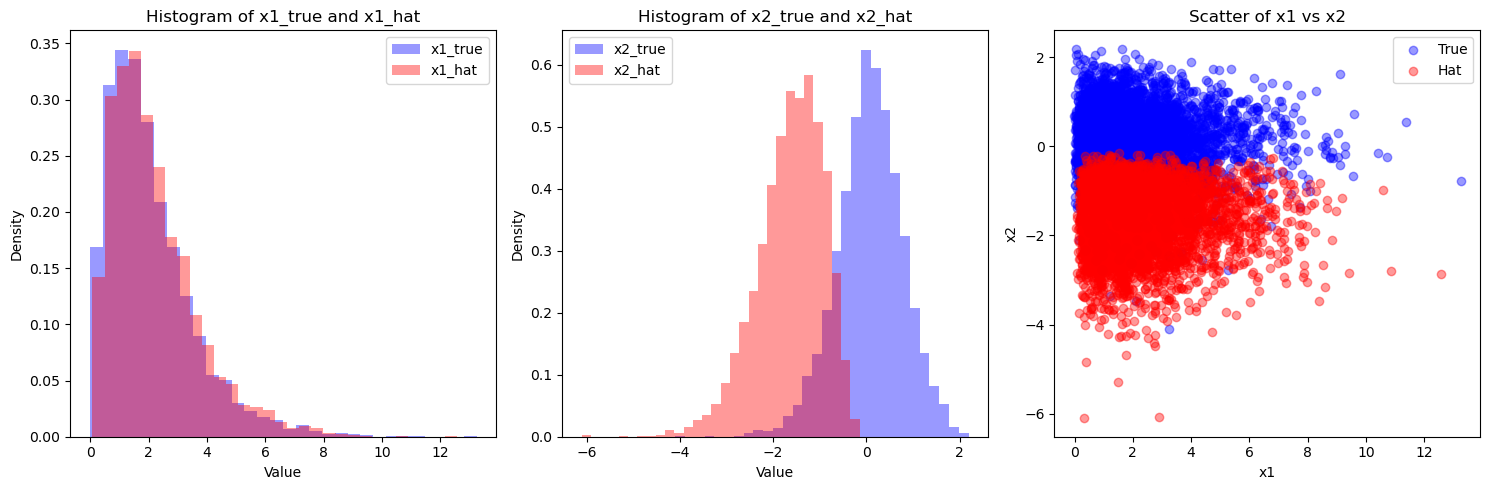

In [47]:
x1_true = generate_data(n_samples=5000, A_true=A_true[0].unsqueeze(0))
x1_hat = generate_data(n_samples=5000, A_true=torch.tensor(A_hat[0],dtype=torch.float32).unsqueeze(0))
x2_true = generate_data(n_samples=5000, A_true=A_true[1].unsqueeze(0))
x2_hat = generate_data(n_samples=5000, A_true=torch.tensor(A_hat[1],dtype=torch.float32).unsqueeze(0))
x1_true = x1_true[:, 0].numpy()  # Shape: (5000,)
x1_hat = x1_hat[:, 0].numpy()    # Shape: (5000,)
x2_true = x2_true[:, 0].numpy()  # Shape: (5000,)
x2_hat = x2_hat[:, 0].numpy()    # Shape: (5000,)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))  

axes[0].hist(x1_true, bins=30, color='blue', alpha=0.4, label='x1_true', density=True)
axes[0].hist(x1_hat, bins=30, color='red', alpha=0.4, label='x1_hat', density=True)
axes[0].set_xlabel('Value')
axes[0].set_ylabel('Density')
axes[0].set_title('Histogram of x1_true and x1_hat')
axes[0].legend()

axes[1].hist(x2_true, bins=30, color='blue', alpha=0.4, label='x2_true', density=True)
axes[1].hist(x2_hat, bins=30, color='red', alpha=0.4, label='x2_hat', density=True)
axes[1].set_xlabel('Value')
axes[1].set_ylabel('Density')
axes[1].set_title('Histogram of x2_true and x2_hat')
axes[1].legend()

axes[2].scatter(x1_true, x2_true, color='blue', alpha=0.4, label='True')
axes[2].scatter(x1_hat, x2_hat, color='red', alpha=0.4, label='Hat')
axes[2].set_xlabel('x1')
axes[2].set_ylabel('x2')
axes[2].set_title('Scatter of x1 vs x2')
axes[2].legend()

plt.tight_layout()
plt.show()

In [ ]:
## the distributions of S1,S2 are unknown; noise-free ICA 

In [49]:
model_formula_X = "x1 <- s1 + s2; x2 <- s1 + s2"
model_formula_S = "u1, u2 ~ Uniform(0.0, 1.0); s1 <- n(u1); s2 <- n(u2);"
model_formula = model_formula_S + model_formula_X
model = SEM2(model_formula)
observed_var = ["x1", "x2"]
observed_index = [list(model.static_order()).index(var) for var in observed_var]
model = SEM2(model_formula)
optimizer = torch.optim.Adam(model.parameters(), lr=5e-3)
model.train()
niter = 8000
for i in range(niter):
    optimizer.zero_grad()
    sample = model(X.size(0) * 3)[:, observed_index]
    loss, s1, s2 = energy_loss(X, sample,beta=1)
    loss.backward()
    optimizer.step()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')

model.eval()

A_hat = np.zeros([len(observed_var), len(observed_var)])
with torch.no_grad(): 
    for j, node in enumerate(observed_var):
        if model.node_dict[node] is not None:
            weights = model.node_dict[node].weight_matrix()[0].detach().cpu().numpy()
            A_hat[j, :] = weights.flatten()

AE = Amari_error(A_hat, A_true)
print(f"Amari_error: {AE:.4f}")

Iter 1 | loss: 2.4707, s1: 2.4754, s2: 0.0095
Iter 1000 | loss: 0.9377, s1: 1.8742, s2: 1.8730
Iter 2000 | loss: 0.9428, s1: 1.8718, s2: 1.8582
Iter 3000 | loss: 0.9422, s1: 1.8449, s2: 1.8055
Iter 4000 | loss: 0.9502, s1: 1.8676, s2: 1.8348
Iter 5000 | loss: 0.9413, s1: 1.8662, s2: 1.8499
Iter 6000 | loss: 0.9424, s1: 1.8587, s2: 1.8326
Iter 7000 | loss: 0.9436, s1: 1.8765, s2: 1.8657
Iter 8000 | loss: 0.9351, s1: 1.9147, s2: 1.9591
Amari_error: 0.0693


In [ ]:
##the distributions of S1,S2 are unknown; homo_noisy ICA

In [51]:
n_components=2
cdn=3
A_true = generate_mixing_matrix(n_components, cdn)
Sigma=torch.diag(torch.tensor([0.25,0.64],dtype=torch.float32))
X = generate_data(n_samples=5000, A_true=A_true,Sigma=Sigma)

In [59]:
model_formula_X = "e1 ~ Normal(0.0, 0.5); e2 ~ Normal(0.0, 0.8); x1 <- 1*e1 + s1 + s2; x2 <- 1*e2 + s1 + s2"
model_formula_S = "u1, u2 ~ Uniform(0.0, 1.0); s1 <- n(u1); s2 <- n(u2);"
model_formula = model_formula_S + model_formula_X
model = SEM2(model_formula)
observed_var = ["x1", "x2"]
observed_index = [list(model.static_order()).index(var) for var in observed_var]
model = SEM2(model_formula)
optimizer = torch.optim.Adam(model.parameters(), lr=5e-3)
model.train()
niter = 8000
for i in range(niter):
    optimizer.zero_grad()
    sample = model(X.size(0) * 3)[:, observed_index]
    loss, s1, s2 = energy_loss(X, sample,beta=1)
    loss.backward()
    optimizer.step()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')

model.eval()

A_hat = np.zeros([len(observed_var), len(observed_var)])
with torch.no_grad(): 
    for j, node in enumerate(observed_var):
        if model.node_dict[node] is not None:
            weights = model.node_dict[node].weight_matrix()[0].detach().cpu().numpy().flatten()
            A_hat[j, :] = weights[1:(1+len(observed_var))]

AE = Amari_error(A_hat, A_true)
print(f"Amari_error: {AE:.4f}")

Iter 1 | loss: 5.5763, s1: 6.1625, s2: 1.1723
Iter 1000 | loss: 2.3722, s1: 4.7220, s2: 4.6995
Iter 2000 | loss: 2.3902, s1: 4.6875, s2: 4.5946
Iter 3000 | loss: 2.3516, s1: 4.5822, s2: 4.4611
Iter 4000 | loss: 2.3911, s1: 4.6906, s2: 4.5991
Iter 5000 | loss: 2.4224, s1: 4.6567, s2: 4.4686
Iter 6000 | loss: 2.3781, s1: 4.6842, s2: 4.6122
Iter 7000 | loss: 2.4155, s1: 4.7949, s2: 4.7587
Iter 8000 | loss: 2.3402, s1: 4.8181, s2: 4.9558
Amari_error: 0.0488


In [61]:
print(A_true)
print(A_hat)

tensor([[ 1.1790, -1.1074],
        [ 2.7173, -0.0078]])
[[ 0.23063445 -0.31748211]
 [ 0.53315908  0.05972931]]
